# Hotel Booking Cancellation Prediction
Predict whether a hotel booking will be canceled (`is_canceled`) using classification models.

**Data:** Hotel Booking Demand (Kaggle), file `hotel_bookings.csv`

**Steps:** explore the data, find and remove data leakage, build a preprocessing + model Pipeline,
compare 3 models, tune the best one, and read the results.

## Importing the libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Importing the dataset


In [ ]:
dataset = pd.read_csv('hotel_bookings.csv')
print(dataset.shape)
print(dataset.head())

Saving hotel_bookings.csv to hotel_bookings.csv
(119390, 32)
          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                       

## Exploring the data

In [ ]:
print(dataset.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
# How many bookings were canceled? (our target)
print(dataset['is_canceled'].value_counts())
print(dataset['is_canceled'].value_counts(normalize=True).round(3))

is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64


In [ ]:
# Which columns have missing values?
missing = dataset.isnull().sum()
print(missing[missing > 0])

children         4
country        488
agent        16340
company     112593
dtype: int64


## Finding data leakage
`reservation_status` tells us the final status of the booking (Canceled, Check-Out, No-Show).
That is information we only know AFTER the outcome, so it cannot be used to predict it.

In [ ]:
print(pd.crosstab(dataset['reservation_status'], dataset['is_canceled']))

is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207


In [ ]:
# Experiment: what happens if we keep the leaky column?
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

demo = dataset[['reservation_status', 'lead_time', 'is_canceled']].copy()
demo['reservation_status'] = demo['reservation_status'].astype('category').cat.codes

X_demo = demo.drop('is_canceled', axis=1)
y_demo = demo['is_canceled']
X_demo_train, X_demo_test, y_demo_train, y_demo_test = train_test_split(
    X_demo, y_demo, test_size=0.2, random_state=42)

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_demo_train, y_demo_train)
print('Accuracy WITH the leaky column:', round(accuracy_score(y_demo_test, tree.predict(X_demo_test)), 4))

Accuracy WITH the leaky column: 1.0


A tiny tree reaches almost perfect accuracy. That is not a good model, that is a model that cheats.
We remove the leaky columns (`reservation_status`, `reservation_status_date`).
`company` is also removed because almost all of its values are missing.

In [ ]:
dataset = dataset.drop(['reservation_status', 'reservation_status_date', 'company'], axis=1)

# agent is an ID, not a number: treat it as a category (0 = no agent)
dataset['agent'] = dataset['agent'].fillna(0).astype(int).astype(str)

print(dataset.shape)

(119390, 29)


## Splitting into features (X), target (y) and training/test sets

In [ ]:
X = dataset.drop('is_canceled', axis=1)
y = dataset['is_canceled']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

(95512, 28) (23878, 28)


In [ ]:
# Numeric and categorical columns
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

print('Numeric columns:', len(num_cols))
print('Categorical columns:', len(cat_cols), cat_cols)

Numeric columns: 17
Categorical columns: 11 ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'agent', 'customer_type']


## Building the preprocessing


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

## Training 3 models
Each model is wrapped in a Pipeline: preprocessing + classifier.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6,
                             random_state=42, n_jobs=-1, eval_metric='logloss')
}

results = []
for name, classifier in models.items():
    pipe = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('classifier', classifier)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })
    print(name, 'done')

results_df = pd.DataFrame(results).round(3)
print(results_df)
results_df.to_csv('model_comparison.csv', index=False)

Logistic Regression done
Random Forest done
XGBoost done
                 Model  Accuracy  Precision  Recall     F1  ROC-AUC
0  Logistic Regression     0.831      0.812   0.709  0.757    0.913
1        Random Forest     0.895      0.895   0.813  0.852    0.959
2              XGBoost     0.876      0.860   0.795  0.827    0.950


## k-Fold Cross Validation
We check that the scores are stable and not just lucky on one split (5 folds, training data only).

In [ ]:
from sklearn.model_selection import cross_val_score

for name, classifier in models.items():
    pipe = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('classifier', classifier)
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='f1')
    print(f'{name}: F1 = {scores.mean():.3f} (+/- {scores.std():.3f})')

Logistic Regression: F1 = 0.759 (+/- 0.004)
Random Forest: F1 = 0.846 (+/- 0.005)
XGBoost: F1 = 0.827 (+/- 0.002)


## Grid Search
We tune XGBoost. In a Pipeline, a parameter name is: step name + two underscores + parameter name.

In [ ]:
from sklearn.model_selection import GridSearchCV

xgb_pipe = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', XGBClassifier(learning_rate=0.1, random_state=42, n_jobs=-1,
                                 eval_metric='logloss'))
])

parameters = {
    'classifier__n_estimators': [200, 400],
    'classifier__max_depth': [4, 6]
}

grid_search = GridSearchCV(estimator=xgb_pipe, param_grid=parameters,
                           scoring='f1', cv=3, n_jobs=1)
grid_search.fit(X_train, y_train)

print('Best F1 (cross-validation):', round(grid_search.best_score_, 3))
print('Best parameters:', grid_search.best_params_)

Best F1 (cross-validation): 0.832
Best parameters: {'classifier__max_depth': 6, 'classifier__n_estimators': 400}


## Final evaluation on the test set

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Final model: Random Forest (best F1 in cross-validation)
final_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', clone(models['Random Forest']))
])
final_model.fit(X_train, y_train)

# Compare with the tuned XGBoost on the test set
for name, m in [('Random Forest', final_model), ('Tuned XGBoost', grid_search.best_estimator_)]:
    y_pred = m.predict(X_test)
    y_proba = m.predict_proba(X_test)[:, 1]
    print(f'{name}: F1 = {f1_score(y_test, y_pred):.3f}, ROC-AUC = {roc_auc_score(y_test, y_proba):.3f}')

y_pred = final_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=['Not canceled', 'Canceled']))

Random Forest: F1 = 0.852, ROC-AUC = 0.959
Tuned XGBoost: F1 = 0.832, ROC-AUC = 0.953
              precision    recall  f1-score   support

Not canceled       0.90      0.94      0.92     15033
    Canceled       0.89      0.81      0.85      8845

    accuracy                           0.90     23878
   macro avg       0.90      0.88      0.89     23878
weighted avg       0.90      0.90      0.89     23878



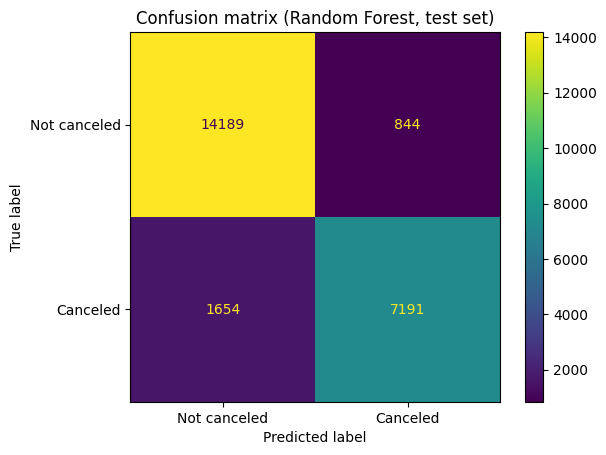

In [ ]:
ConfusionMatrixDisplay.from_estimator(final_model, X_test, y_test,
                                      display_labels=['Not canceled', 'Canceled'])
plt.title('Confusion matrix (Random Forest, test set)')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## Which features matter most?

num__lead_time                      0.1009
cat__deposit_type_No Deposit        0.0634
num__adr                            0.0627
cat__country_PRT                    0.0613
cat__deposit_type_Non Refund        0.0570
num__total_of_special_requests      0.0544
num__arrival_date_day_of_month      0.0485
num__arrival_date_week_number       0.0430
num__stays_in_week_nights           0.0348
num__previous_cancellations         0.0230
num__stays_in_weekend_nights        0.0230
num__arrival_date_year              0.0209
num__required_car_parking_spaces    0.0182
num__booking_changes                0.0181
cat__agent_9                        0.0174
dtype: float64


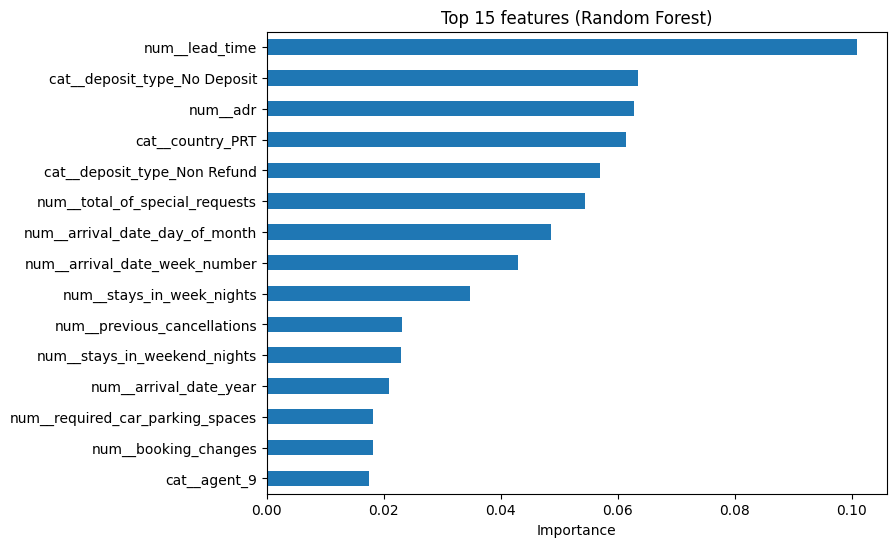

In [ ]:
feature_names = final_model.named_steps['preprocessor'].get_feature_names_out()
importances = final_model.named_steps['classifier'].feature_importances_

top = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(15)
print(top.round(4))

top.sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Top 15 features (Random Forest)')
plt.xlabel('Importance')
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()